**The German International University of Applied Sciences**

**Faculty of Informatics and Computer Science**

**Data Engineering and visualisation**

**Project 1**

In this project, we will try to uncover relationships between afforfable housing and the Serious Injury Response, Tracking and Analysis (SIRTA) programme in New York City (NYC).

We selected these data sets:
- Affordable Housing Production by Building (H2)
- SIRTA Data (T4)

### Setting Everything Up

The first step is to import all needed libraries.

In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

The next thing to do is to load the data sets into Pandas DataFrame data structures.

In [26]:
df_housing = pd.read_csv("datasets/Affordable_Housing_Production_by_Building_20261108.csv")
df_transport = pd.read_csv("datasets/Serious_Injury_Response,_Tracking_&_Analysis_Program_(SIRTA)_20261108.csv")

#### Explore

This section performs exploratory data analysis.

The first thing we do is understand the structure of the data.

##### Housing Data Set

Exploring the structure


In [27]:
print("Rows: ", df_housing.shape[0])
print("Cols: ", df_housing.shape[1])

Rows:  9551
Cols:  41


In [28]:
print("Column information:")
df_housing.info();

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 41 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Project ID                          9551 non-null   int64  
 1   Project Name                        9551 non-null   str    
 2   Project Start Date                  9551 non-null   str    
 3   Project Completion Date             7732 non-null   str    
 4   Building ID                         7602 non-null   float64
 5   Number                              9551 non-null   str    
 6   Street                              9551 non-null   str    
 7   Borough                             9551 non-null   str    
 8   Postcode                            7593 non-null   float64
 9   BBL                                 7530 non-null   float64
 10  BIN                                 7530 non-null   float64
 11  Community Board                   

In [29]:
print("Missing values:")
missing = df_housing.isnull().sum()
display(missing[missing > 0])

Missing values:


Project Completion Date               1819
Building ID                           1949
Postcode                              1958
BBL                                   2021
BIN                                   2021
Census Tract                          1958
NTA - Neighborhood Tabulation Area    1958
Latitude                              1958
Longitude                             1958
Latitude (Internal)                   2044
Longitude (Internal)                  2044
Building Completion Date              1666
Extremely Low Income Units            7470
Very Low Income Units                 6151
Low Income Units                      4046
Moderate Income Units                 7857
Middle Income Units                   6860
Other Income Units                    8191
Studio Units                          6353
1-BR Units                            3439
2-BR Units                            3509
3-BR Units                            6122
4-BR Units                            8990
5-BR Units 

In [30]:
print("Duplicate records: ", df_housing.duplicated().sum())

Duplicate records:  0


Exploring the statistics

In [31]:
print("Column statistics:")
display(df_housing.describe(include="all").T)

Column statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Project ID,9551.0,NaN,NaN,NaN,67125.247409,8463.040347,44218.0,61418.5,68781.0,73850.5,82249.0
Project Name,9551,3979,CONFIDENTIAL,1949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Project Start Date,9551,2346,06/30/2021,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Project Completion Date,7732,2066,06/20/2019,103,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Building ID,7602.0,NaN,NaN,NaN,582729.711655,401057.617968,375.0,117976.25,805625.5,980688.75,1022537.0
Number,9551,3154,----,1949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Street,9551,1567,----,1949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Borough,9551,5,Brooklyn,3649,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Postcode,7593.0,NaN,NaN,NaN,10780.411432,504.437572,10001.0,10453.0,11102.0,11221.0,11694.0
BBL,7530.0,NaN,NaN,NaN,2510121977.677689,972093306.509762,1000050010.0,2026850033.0,3008497502.0,3039567554.5,5080477501.0


In [32]:
print("Numeric column minimums and maximums:")
numeric_columns = df_housing.select_dtypes(include="number").columns
display(df_housing[numeric_columns].agg(["min", "max"]).T)

Numeric column minimums and maximums:


,min,max
Project ID,4.421800e+04,8.224900e+04
Building ID,3.750000e+02,1.022537e+06
Postcode,1.000100e+04,1.169400e+04
BBL,1.000050e+09,5.080478e+09
BIN,1.000000e+06,5.174441e+06
Council District,1.000000e+00,5.100000e+01
Census Tract,1.000000e+00,1.227040e+05
Latitude,4.050991e+01,4.090663e+01
Longitude,-7.424769e+01,-7.373062e+01
Latitude (Internal),4.051005e+01,4.090688e+01


In [33]:
print("Rows with negative unit counts:")

unit_columns = [column for column in df_housing.columns if "unit" in column.lower()]
unit_counts = df_housing[unit_columns].apply(pd.to_numeric, errors="coerce")

display(df_housing.loc[(unit_counts < 0).any(axis=1), unit_columns])

Rows with negative unit counts:


,Community Board,Extremely Low Income Units,Very Low Income Units,Low Income Units,Moderate Income Units,Middle Income Units,Other Income Units,Studio Units,1-BR Units,2-BR Units,3-BR Units,4-BR Units,5-BR Units,6-BR+ Units,Unknown-BR Units,Counted Rental Units,Counted Homeownership Units,All Counted Units,Total Units


Exploring linear correlation between all columns

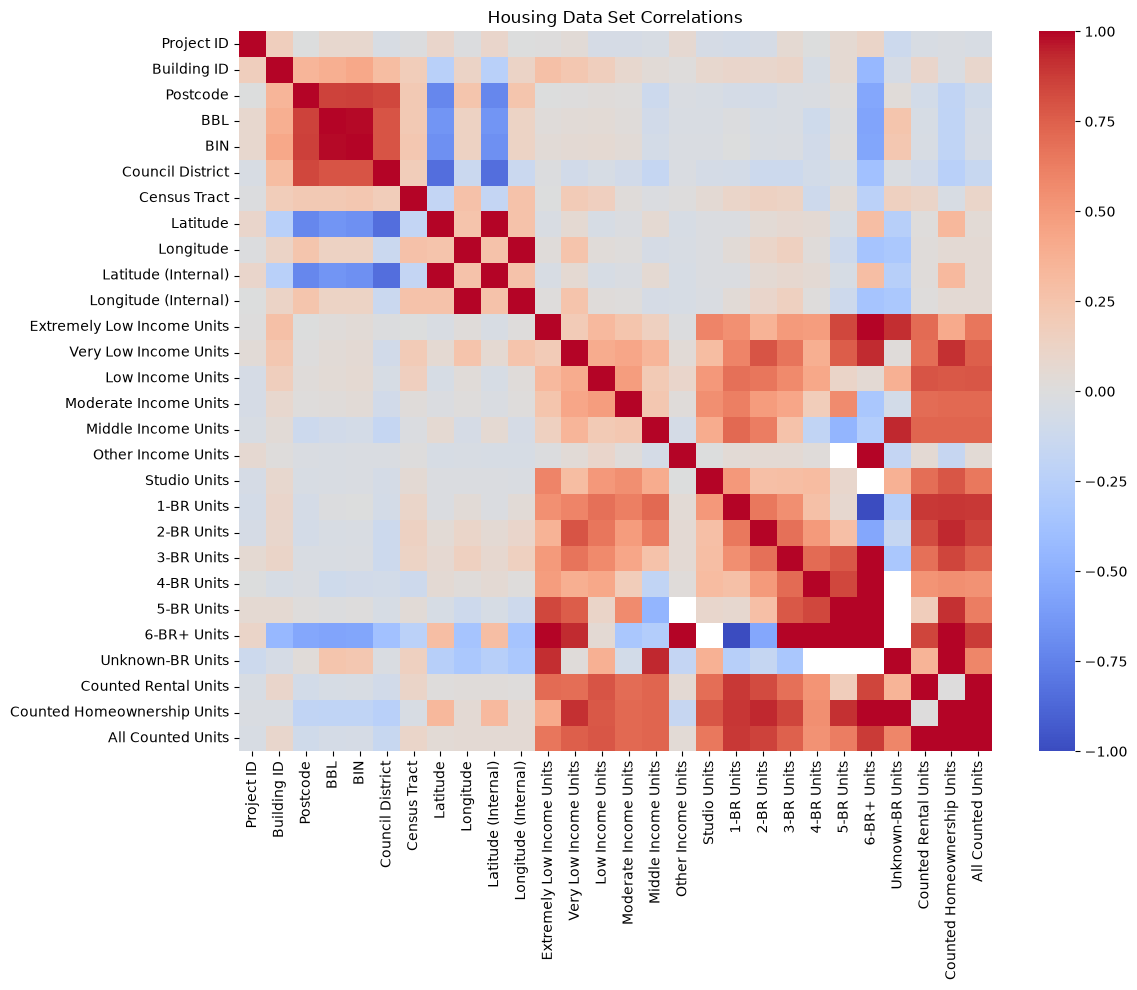

In [34]:
housing_correlations = df_housing.corr(numeric_only=True)

plt.figure(figsize=(12, 10))
sns.heatmap(housing_correlations, cmap="coolwarm", center=0)
plt.title("Housing Data Set Correlations")
plt.tight_layout()
plt.show()

##### Serious Injury Response Data Set

Exploring the structure


In [35]:
print("Rows: ", df_transport.shape[0])
print("Cols: ", df_transport.shape[1])

Rows:  13754
Cols:  23


In [36]:
print("Column information:")
df_transport.info();

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 13754 entries, 0 to 13753
Data columns (total 23 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   Collision ID                                        13310 non-null  float64
 1   Crash Date                                          13310 non-null  str    
 2   Crash Time                                          13310 non-null  str    
 3   Crash Police Precinct                               13310 non-null  float64
 4   Crash Borough                                       13255 non-null  str    
 5   Total Non-Severe Injuries                           13310 non-null  float64
 6   Total Severe Injuries                               13310 non-null  float64
 7   Total Fatalities                                    13310 non-null  float64
 8   Latitude                                            10868 non-null 

In [37]:
print("Missing values:")
missing = df_transport.isnull().sum()
display(missing[missing > 0])

Missing values:


Collision ID                                            444
Crash Date                                              444
Crash Time                                              444
Crash Police Precinct                                   444
Crash Borough                                           499
Total Non-Severe Injuries                               444
Total Severe Injuries                                   444
Total Fatalities                                        444
Latitude                                               2886
Longitude                                              2886
On Street                                              3036
Cross Street                                           5642
Address                                               11177
Highway Reference Marker                              12702
ZipCode                                                5682
Similar Fatalities & Severe Injuries (3Y Lookback)     1837
Similar Fatalities & All Injuries (3Y Lo

In [38]:
print("Duplicate records: ", df_transport.duplicated().sum())

Duplicate records:  3


Exploring the statistics

In [39]:
print("Column statistics:")
display(df_transport.describe(include="all").T);

Column statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Collision ID,13310.0,NaN,NaN,NaN,7271532.868295,11289301.231011,2126022.0,4612503.25,4718837.5,4814222.75,121326075.0
Crash Date,13310,1641,05/21/2022,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crash Time,13310,1728,00:00,186,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crash Police Precinct,13310.0,NaN,NaN,NaN,67.837866,34.683947,1.0,42.0,68.0,104.0,123.0
Crash Borough,13255,5,Brooklyn,3954,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Non-Severe Injuries,13310.0,NaN,NaN,NaN,0.270473,0.836031,0.0,0.0,0.0,0.0,19.0
Total Severe Injuries,13310.0,NaN,NaN,NaN,1.011495,0.451514,0.0,1.0,1.0,1.0,7.0
Total Fatalities,13310.0,NaN,NaN,NaN,0.082795,0.294304,0.0,0.0,0.0,0.0,5.0
Latitude,10868.0,NaN,NaN,NaN,40.730641,0.083378,40.499672,40.667854,40.72671,40.800663,40.912468
Longitude,10868.0,NaN,NaN,NaN,-73.921537,0.081929,-74.24857,-73.96879,-73.923693,-73.874742,-73.7006


In [40]:
print("Numeric column minimums and maximums:")
numeric_columns = df_transport.select_dtypes(include="number").columns
display(df_transport[numeric_columns].agg(["min", "max"]).T)

Numeric column minimums and maximums:


,min,max
Collision ID,2.126022e+06,1.213261e+08
Crash Police Precinct,1.000000e+00,1.230000e+02
Total Non-Severe Injuries,0.000000e+00,1.900000e+01
Total Severe Injuries,0.000000e+00,7.000000e+00
Total Fatalities,0.000000e+00,5.000000e+00
Latitude,4.049967e+01,4.091247e+01
Longitude,-7.424857e+01,-7.370060e+01
ZipCode,1.000000e+04,1.169400e+04
Similar Fatalities & Severe Injuries (3Y Lookback),0.000000e+00,9.000000e+00
Similar Fatalities & All Injuries (3Y Lookback),0.000000e+00,2.960000e+02


In [41]:
print("Rows with negative injury or fatality counts:")
injury_columns = [column for column in df_transport.columns if "injur" in column.lower() or "fatalit" in column.lower()]
display(df_transport.loc[(df_transport[injury_columns] < 0).any(axis=1), injury_columns])

Rows with negative injury or fatality counts:


,Total Non-Severe Injuries,Total Severe Injuries,Total Fatalities,Similar Fatalities & Severe Injuries (3Y Lookback),Similar Fatalities & All Injuries (3Y Lookback)


In [42]:
print("Rows with coordinates outside valid latitude/longitude ranges:")
invalid_coordinates = (
    df_transport["Latitude"].notnull() & ~df_transport["Latitude"].between(-90, 90)
) | (
    df_transport["Longitude"].notnull() & ~df_transport["Longitude"].between(-180, 180)
)
display(df_transport.loc[invalid_coordinates, ["Latitude", "Longitude"]])

Rows with coordinates outside valid latitude/longitude ranges:


,Latitude,Longitude


##### Serious Injury Response Data Set Relationships

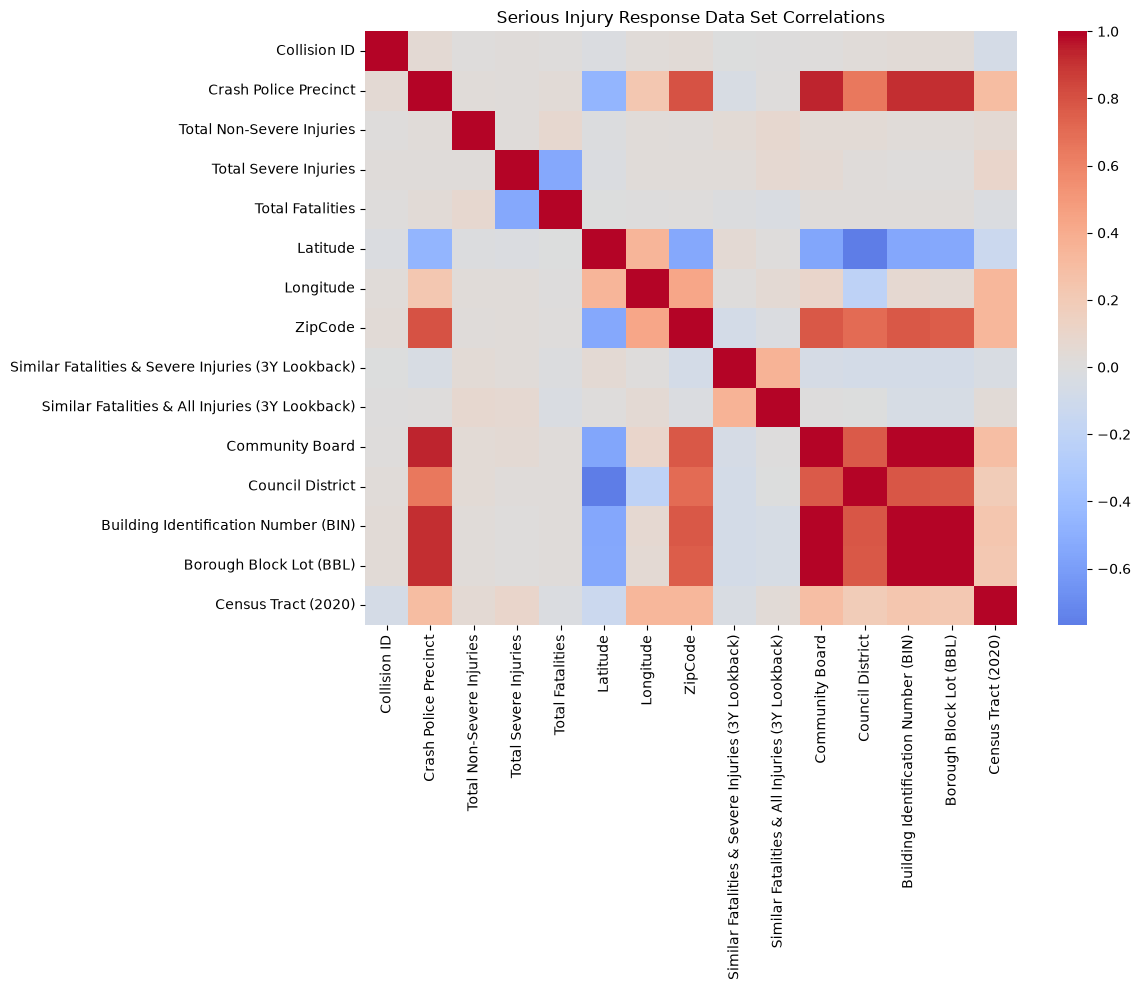

In [43]:
transport_correlations = df_transport.corr(numeric_only=True)

plt.figure(figsize=(12, 10))
sns.heatmap(transport_correlations, cmap="coolwarm", center=0)
plt.title("Serious Injury Response Data Set Correlations")
plt.tight_layout()
plt.show()

#### Transform

The next step in the ETL pipeline is transforming the data. This includes tasks like data cleaning and normalisation.

This trims whitespace, converts names to lowercase, replaces spaces and special characters with underscores, and removes leading or trailing underscores.

In [44]:
for df in [df_housing, df_transport]:
    new_columns = []

    for column in df.columns:
        column = column.strip().lower()
        column = column.replace(" ", "_")

        for character in [",", ".", "-", "/", "(", ")", "&", "+"]:
            column = column.replace(character, "_")

        while "__" in column:
            column = column.replace("__", "_")

        column = column.strip("_")
        new_columns.append(column)

    df.columns = new_columns

Invalid dates are converted to `NaT`.

In [45]:
for df in [df_housing, df_transport]:
    date_columns = [column for column in df.columns if "date" in column]

    for column in date_columns:
        df[column] = pd.to_datetime(df[column], errors="coerce")

Time values are converted to Pandas string type and trimmed.

In [46]:
for df in [df_housing, df_transport]:
    time_columns = [column for column in df.columns if "time" in column]

    for column in time_columns:
        df[column] = df[column].astype("string").str.strip()

Borough values are converted to uppercase strings and trimmed.

In [47]:
for df in [df_housing, df_transport]:
    borough_columns = [column for column in df.columns if "borough" in column]

    for column in borough_columns:
        df[column] = df[column].astype("string").str.strip().str.upper()

#### Load

The last step of the ETL pipeline is loading the transformed data sets.

In [48]:
df_housing.to_csv("datasets/Housing_Cleaned.csv",index=False)
df_transport.to_csv("datasets/Transportation_Cleaned.csv",index=False)